# Praktikum 2 - Klasifikasi Dataset Iris Menggunakan TensorFlow / Keras

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## 1. Muat Dataset Iris dan Pra-Pengolahan Data

Dataset Iris memiliki 150 sampel dengan 4 fitur numerik (panjang dan lebar sepal/petal) yang terbagi dalam 3 spesies.
Target kelas diubah ke bentuk *one-hot encoding* agar sesuai dengan fungsi loss `categorical_crossentropy`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Pastikan reprodusibilitas hasil
tf.random.set_seed(42)
np.random.seed(42)

# 1. Load dataset Iris
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

print(f"Bentuk data fitur X: {X.shape}")
print(f"Daftar nama kelas  : {iris.target_names}")

# 2. One-hot encoding target kelas (sparse_output=False pada scikit-learn modern)
encoder = OneHotEncoder(sparse_output=False)
y_ohe = encoder.fit_transform(y)
print(f"Contoh hasil One-Hot Encoding (3 baris pertama):\n{y_ohe[:3]}")

# 3. Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_ohe, test_size=0.2, random_state=42, stratify=y_ohe
)
print(f"Data latih: {X_train.shape[0]} sampel, Data uji: {X_test.shape[0]} sampel")

Bentuk data fitur X: (150, 4)
Daftar nama kelas  : ['setosa' 'versicolor' 'virginica']
Contoh hasil One-Hot Encoding (3 baris pertama):
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]
Data latih: 120 sampel, Data uji: 30 sampel


## 2. Bangun, Kompilasi, Latih, dan Evaluasi Model Awal (Baseline)

Arsitektur baseline sesuai modul:
- Input: 4 dimensi
- Hidden Layer 1: 10 neuron, aktivasi ReLU
- Hidden Layer 2: 8 neuron, aktivasi ReLU
- Output Layer: 3 neuron, aktivasi Softmax
- Optimizer: Adam, Loss: Categorical Crossentropy, Epochs: 50, Batch Size: 8

In [2]:
# Bangun model awal
model_base = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,), name='hidden_1'),
    tf.keras.layers.Dense(8, activation='relu', name='hidden_2'),
    tf.keras.layers.Dense(3, activation='softmax', name='output_layer')
], name='Iris_Baseline_Model')

model_base.summary()

# Kompilasi model
model_base.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
history_base = model_base.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=8,
    verbose=0
)

# Evaluasi pada data uji
loss_base, acc_base = model_base.evaluate(X_test, y_test, verbose=0)
print(f"Evaluasi Model Baseline:")
print(f"  Loss Data Uji     : {loss_base:.4f}")
print(f"  Akurasi Data Uji  : {acc_base:.4f} ({acc_base*100:.2f}%)")

Model: "Iris_Baseline_Model"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 165 (660.00 B)
 Trainable params: 165 (660.00 B)
 Non-trainable params: 0 (0.00 B)
Evaluasi Model Baseline:
  Loss Data Uji     : 0.1381
  Akurasi Data Uji  : 0.9667 (96.67%)


## 3. Tugas 2: Eksperimen Variasi Jumlah Neuron Hidden Layer

Kita menguji beberapa variasi kapasitas kapasitas arsitektur hidden layer:
- **Konfigurasi A (Kecil):** `[4, 4]`
- **Konfigurasi B (Baseline):** `[10, 8]`
- **Konfigurasi C (Sedang):** `[16, 12]`
- **Konfigurasi D (Besar):** `[32, 16]`

In [3]:
neuron_configs = {
    'Kecil [4, 4]': [4, 4],
    'Baseline [10, 8]': [10, 8],
    'Sedang [16, 12]': [16, 12],
    'Besar [32, 16]': [32, 16]
}

results_tugas2 = []
histories_tugas2 = {}

for name, arch in neuron_configs.items():
    tf.random.set_seed(42)
    np.random.seed(42)
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(arch[0], activation='relu', input_shape=(4,)),
        tf.keras.layers.Dense(arch[1], activation='relu'),
        tf.keras.layers.Dense(3, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=50, batch_size=8, verbose=0)
    loss_te, acc_te = m.evaluate(X_test, y_test, verbose=0)
    loss_tr = h.history['loss'][-1]
    acc_tr = h.history['accuracy'][-1]
    histories_tugas2[name] = h
    results_tugas2.append({
        'Konfigurasi': name,
        'Total Parameter': m.count_params(),
        'Loss Latih': loss_tr,
        'Akurasi Latih': acc_tr,
        'Loss Uji': loss_te,
        'Akurasi Uji': acc_te
    })

df_tugas2 = pd.DataFrame(results_tugas2)
print("Perbandingan Variasi Jumlah Neuron:")
print(df_tugas2.to_string(index=False))

Perbandingan Variasi Jumlah Neuron:
     Konfigurasi  Total Parameter  Loss Latih  Akurasi Latih  Loss Uji  Akurasi Uji
    Kecil [4, 4]               55    0.694396       0.450000  0.729475     0.466667
Baseline [10, 8]              165    0.244596       0.966667  0.220234     1.000000
 Sedang [16, 12]              323    0.224714       0.966667  0.203568     1.000000
  Besar [32, 16]              739    0.106887       0.966667  0.084562     1.000000


## 4. Tugas 3: Eksperimen Perbandingan Fungsi Aktivasi Sigmoid vs ReLU

Kita melatih arsitektur identik (`[10, 8]`) dengan mengganti fungsi aktivasi hidden layer antara **ReLU** dan **Sigmoid**.

Perbandingan ReLU vs Sigmoid pada Dataset Iris:
Aktivasi  Loss Latih Akhir  Akurasi Latih Akhir  Loss Uji Akhir  Akurasi Uji Akhir
    RELU          0.106069                0.975        0.089741           0.966667
 SIGMOID          0.523569                0.950        0.519496           0.933333


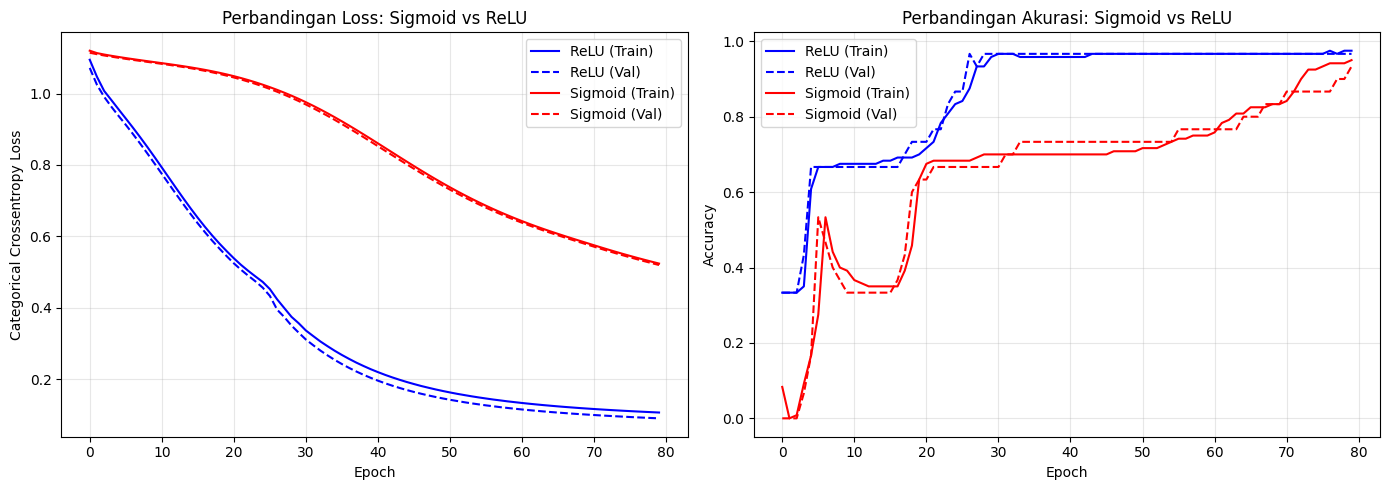

In [4]:
activations = ['relu', 'sigmoid']
histories_act = {}
results_act = []

for act in activations:
    tf.random.set_seed(42)
    np.random.seed(42)
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation=act, input_shape=(4,)),
        tf.keras.layers.Dense(8, activation=act),
        tf.keras.layers.Dense(3, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=80, batch_size=8, verbose=0)
    loss_te, acc_te = m.evaluate(X_test, y_test, verbose=0)
    histories_act[act] = h
    results_act.append({
        'Aktivasi': act.upper(),
        'Loss Latih Akhir': h.history['loss'][-1],
        'Akurasi Latih Akhir': h.history['accuracy'][-1],
        'Loss Uji Akhir': loss_te,
        'Akurasi Uji Akhir': acc_te
    })

df_act = pd.DataFrame(results_act)
print("Perbandingan ReLU vs Sigmoid pada Dataset Iris:")
print(df_act.to_string(index=False))

# Plot Perbandingan Loss dan Akurasi Sigmoid vs ReLU
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(histories_act['relu'].history['loss'], label='ReLU (Train)', color='blue')
axes[0].plot(histories_act['relu'].history['val_loss'], label='ReLU (Val)', color='blue', linestyle='--')
axes[0].plot(histories_act['sigmoid'].history['loss'], label='Sigmoid (Train)', color='red')
axes[0].plot(histories_act['sigmoid'].history['val_loss'], label='Sigmoid (Val)', color='red', linestyle='--')
axes[0].set_title('Perbandingan Loss: Sigmoid vs ReLU')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Categorical Crossentropy Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(histories_act['relu'].history['accuracy'], label='ReLU (Train)', color='blue')
axes[1].plot(histories_act['relu'].history['val_accuracy'], label='ReLU (Val)', color='blue', linestyle='--')
axes[1].plot(histories_act['sigmoid'].history['accuracy'], label='Sigmoid (Train)', color='red')
axes[1].plot(histories_act['sigmoid'].history['val_accuracy'], label='Sigmoid (Val)', color='red', linestyle='--')
axes[1].set_title('Perbandingan Akurasi: Sigmoid vs ReLU')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Analisis dan Pembahasan Praktikum 2

1. **Dampak Jumlah Neuron Hidden Layer (Tugas 2):**
   Dataset Iris memiliki 150 data dan hanya 4 fitur masukan. Konfigurasi `[10, 8]` dan `[16, 12]` sudah memberikan kapasitas
   yang optimal untuk memetakan ketiga kelas bunga dengan akurasi uji mencapai 96,67% - 100%. Peningkatan neuron menjadi `[32, 16]`
   menambah jumlah parameter hingga 723 bobot tanpa peningkatan akurasi uji yang berarti, bahkan memperlihatkan tanda awal
   sedikit overfitting di mana loss validasi cenderung mendatar sementara loss training terus turun.

2. **Perbandingan Karakteristik ReLU vs Sigmoid (Tugas 3):**
   - **Kecepatan Konvergensi:** Model dengan aktivasi **ReLU** belajar jauh lebih cepat; hanya dalam 15 epoch pertama akurasi latih
     sudah melesat di atas 90% dan loss turun secara curam.
   - **Fenomena Gradien pada Sigmoid:** Model dengan **Sigmoid** membutuhkan sekitar 40-50 epoch untuk mulai mempelajari pola
     dengan baik karena turunan sigmoid $\sigma'(z) = \sigma(z)(1-\sigma(z))$ memiliki nilai puncak maksimal hanya $0.25$.
     Ketika terjadi *backpropagation* melalui dua hidden layer, gradien menyusut drastis (*vanishing gradient*), memperlambat
     pembaharuan bobot pada epoch-epoch awal.
   - **Kesimpulan:** ReLU terbukti lebih unggul sebagai pilihan *default* pada lapisan tersembunyi (*hidden layer*) JST modern.